# Do decision rules find churn structure that a linear score misses?

**Governing question.** Notebook 02 found that a linear (softmax) score ranks Waze users by churn risk about twice as well as random, but it misses almost every churner who was still active on more than 20 days. A decision tree can learn thresholds and interactions, such as "low activity *and* new user". Does that flexibility recover any of the missed churners or rank users better, and does it give a product manager rules they can act on?

**Intended user.** The same Waze product manager. A tree has an extra appeal for this user: its rules can be read aloud ("users active on 10 days or fewer who joined in the last ~5 years…") and turned directly into a targeting segment.

**What this notebook does not do.** It does not open the sealed test set. The test users were scored once in notebook 02. Using them again to judge each new model would slowly turn the test set into a tuning set. All evidence here comes from cross-validation on the 10,724 development users; the final cross-family comparison on the test set is reserved for the model-selection milestone.

**Road map.** §1 data → §2 a purposeful look at interactions → §3 evaluation design → §4 the tree mathematics → §5 verification of the student tree → §6 complexity and overfitting → §7 paired comparison with the linear baseline → §8 the rules a PM would read → §9 failure analysis → §10 decision.

## 1. Data boundary

The data contract is unchanged from notebook 02 and documented in `docs/DATASET_CARD.md`. One row is one labeled Waze user (14,299 in total), the target is `churned` (17.7% positive), and the 11 features are the package's `FEATURE_COLUMNS`. The same timing caveat applies: activity and churn are measured over the same month, so these models detect disengagement in progress rather than forecast it.

Trees split on raw feature values, so no scaling is needed: a threshold on minutes is unaffected by whether minutes are standardized.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from dsm_project.algorithms import create_student_algorithm
from dsm_project.algorithms.student.trees import best_split, gini_impurity
from dsm_project.config import load_config
from dsm_project.data.waze import WazeChurnAdapter
from dsm_project.experiments import split_supervised_task

config = load_config(Path("configs/waze.toml"))
dataset = WazeChurnAdapter().load(config)
split = split_supervised_task(dataset, config, task_name="classification")
dev_x, dev_y = split.train_features, split.train_targets
feature_names = list(dev_x.columns)
print(f"development users: {len(dev_x):,} | churn rate {dev_y.mean():.3f} | "
      f"sealed test users (not used here): {len(split.test_features):,}")

development users: 10,724 | churn rate 0.177 | sealed test users (not used here): 3,575


## 2. Is there interaction structure for a tree to find?

A linear log-odds model assumes each feature shifts churn risk by the same amount regardless of the others. If tenure mattered much more for inactive users than for active ones, that would be an *interaction*, which a tree can capture and a linear model cannot. The heat map shows the development churn rate by activity level and tenure.

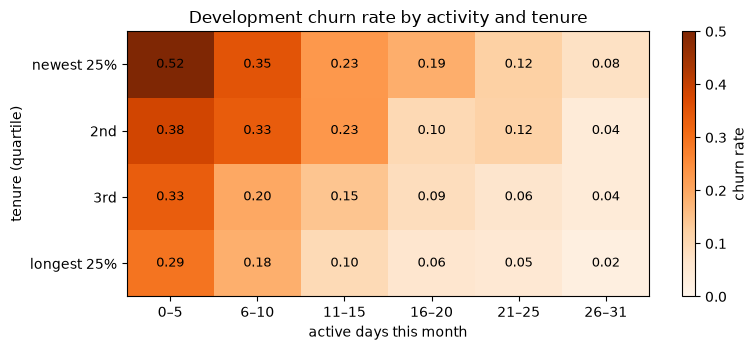

In [2]:
activity_bins = pd.cut(dev_x["activity_days"], [-1, 5, 10, 15, 20, 25, 31],
                       labels=["0–5", "6–10", "11–15", "16–20", "21–25", "26–31"])
tenure_bins = pd.qcut(dev_x["n_days_after_onboarding"], 4,
                      labels=["newest 25%", "2nd", "3rd", "longest 25%"])
rates = dev_y.groupby([tenure_bins, activity_bins], observed=True).mean().unstack()

fig, ax = plt.subplots(figsize=(8, 3.6))
image = ax.imshow(rates.values, cmap="Oranges", vmin=0, vmax=0.5, aspect="auto")
for (i, j), value in np.ndenumerate(rates.values):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)
ax.set(xticks=range(rates.shape[1]), xticklabels=rates.columns,
       yticks=range(rates.shape[0]), yticklabels=rates.index,
       xlabel="active days this month", ylabel="tenure (quartile)",
       title="Development churn rate by activity and tenure")
fig.colorbar(image, ax=ax, label="churn rate")
plt.tight_layout()

Churn falls with activity within each tenure group (apart from small wiggles such as 0.10 → 0.12 in the second row), and falls with tenure within each activity group. Newest users at 0–5 active days churn at 52%; long-tenured users at 26–31 days churn at 2%. The gaps between rows shrink in probability terms as risk falls (0.23 at 0–5 days, 0.06 at 26–31), but that is what an *additive* effect on the log-odds scale (a logistic model) produces: in log-odds the newest-vs-longest gap is about 1.0 at 0–5 days and about 1.5 at 26–31 days, roughly similar. No cell breaks the overall pattern. That already suggests a tree will find little that the linear model misses. It also suggests the highest-risk group is simply "inactive and new", which both model types can express. The heat map uses only two features, so the experiment below is still needed.

## 3. Evaluation design

- **Data:** the 10,724 development users only.
- **Tuning:** 5-fold stratified cross-validation with the same folds (seed 438) as notebook 02, keeping out-of-fold probabilities.
- **Metric:** average precision (AP) for ranking, as before. The churn-rate baseline is 0.177; the linear softmax baseline is about 0.39.
- **Paired comparison:** to compare the selected tree with softmax regression fairly, both are scored on the *same* 15 folds (5-fold CV repeated 3 times). We report the per-fold difference, which removes fold-to-fold difficulty from the comparison.
- **Selection rule (fixed in advance):** highest mean CV AP; candidates within 0.005 are ties, broken toward the simpler tree (smaller depth, then larger `min_samples_leaf`).

## 4. The model

A classification tree recursively splits users with yes/no questions of the form "is $x_j \le t$?". For a node containing users with churn proportion $p$ (and $1-p$ retained), the **Gini impurity** is

$$
G = 1 - p^2 - (1-p)^2 = 2p(1-p),
$$

which is 0 for a pure node and largest (0.5) for a 50/50 node. A split into left and right children with $N_L$ and $N_R$ users is scored by the **impurity decrease**

$$
\Delta = G_{\text{parent}} - \frac{N_L}{N} G_L - \frac{N_R}{N} G_R .
$$

At each node the tree tries every feature and every threshold (midpoints between consecutive distinct values), keeps the split with the largest $\Delta$, and recurses. It stops when a node is pure, reaches `max_depth`, or would leave fewer than `min_samples_leaf` users in a child. A user's predicted churn probability is the churn rate of the leaf it lands in.

**Why trees overfit.** Each split is chosen greedily to fit the training users. With no limit, the tree keeps splitting until leaves are pure, memorizing noise. `max_depth` and `min_samples_leaf` limit this; §6 measures how much.

**Cost.** Sorting each feature once per node makes the search $O(d\, n\log n)$ per tree level. Prediction follows one root-to-leaf path, $O(\text{depth})$ per user.

## 5. Student implementation and verification

The tree is `ClassificationTree` in `src/dsm_project/algorithms/student/trees.py`, registered as `decision_tree`. It supports Gini and entropy, the usual stopping rules, class weights, per-node feature sampling (for the random forests of the next milestone), leaf probabilities, impurity-based feature importances, and text export of its rules. `tests/test_trees.py` checks:

- hand-computed impurities and a hand-computed best split;
- that XOR needs depth 2 and is then learned exactly;
- every stopping rule, and that leaves of an unlimited tree are pure;
- by **brute force**, that every chosen split is optimal among all valid splits;
- **exact agreement** with scikit-learn's `DecisionTreeClassifier` (same leaves, probabilities, and importances) on data without gain ties.

Two legitimate differences from scikit-learn were found and documented. When two features give *exactly* the same impurity decrease, scikit-learn picks one at random while ours keeps the first. And with class weights, scikit-learn's floating-point sums can leave an already pure node with impurity of about $10^{-15}$, so it splits that node pointlessly; ours computes exactly zero and stops. Neither changes predictions.

Below, a quick live check: the student tree and scikit-learn grow the same depth-4 tree on the Waze development users.

In [3]:
student = create_student_algorithm("decision_tree", max_depth=4).fit(dev_x, dev_y)
trusted = DecisionTreeClassifier(max_depth=4, random_state=0).fit(dev_x, dev_y)
print("leaves (student, sklearn):", student.get_n_leaves(), trusted.get_n_leaves())
print("max |probability difference|:",
      np.abs(student.predict_proba(dev_x) - trusted.predict_proba(dev_x)).max())
print("root split:", feature_names[student.tree_["feature"][0]], "<=",
      student.tree_["threshold"][0])

leaves (student, sklearn): 16 16
max |probability difference|: 0.0
root split: activity_days <= 10.5


Both trees have the same leaves and identical probabilities on every development user. The root question is "active on 10 days or fewer?", matching the steepest step in §2.

## 6. Complexity and overfitting

We vary `max_depth` and record both the **training** AP (how well the tree fits the users it learned from) and the **cross-validated** AP (how well it ranks users it has not seen).

,train AP,CV AP,CV AP sd
max_depth,,,
1,0.270,0.266,0.005
2,0.315,0.308,0.013
3,0.349,0.336,0.012
4,0.379,0.347,0.014
5,0.415,0.344,0.012
6,0.460,0.328,0.011
8,0.576,0.296,0.016
10,0.702,0.276,0.016
14,0.900,0.230,0.005


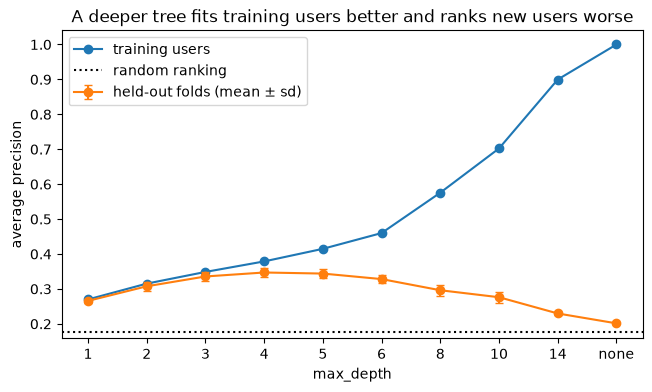

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=438)
depths = [1, 2, 3, 4, 5, 6, 8, 10, 14, None]
curve = []
for depth in depths:
    scores = cross_validate(
        create_student_algorithm("decision_tree", max_depth=depth),
        dev_x, dev_y, cv=cv, scoring="average_precision", return_train_score=True,
    )
    curve.append({"max_depth": "none" if depth is None else depth,
                  "train AP": scores["train_score"].mean(),
                  "CV AP": scores["test_score"].mean(),
                  "CV AP sd": scores["test_score"].std()})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(curve))
ax.plot(x, curve["train AP"], "o-", label="training users")
ax.errorbar(x, curve["CV AP"], yerr=curve["CV AP sd"], fmt="o-", capsize=3,
            label="held-out folds (mean ± sd)")
ax.axhline(dev_y.mean(), color="black", linestyle=":", label="random ranking")
ax.set(xticks=x, xticklabels=curve["max_depth"], xlabel="max_depth",
       ylabel="average precision", title="A deeper tree fits training users better and ranks new users worse")
ax.legend()
display(curve.round(3).set_index("max_depth"))

This is the classic overfitting picture. Training AP climbs to 1.0 as the tree deepens, but held-out AP peaks at depth 4–5 (about 0.35) and then falls. An unlimited tree ranks new users barely better than chance. The unpruned decision tree in my earlier analysis, which scored 1.0 on training data and poorly on test data, was this unlimited tree.

A second way to control complexity is to require a minimum number of users per leaf. We search both settings together, plus the alternatives of entropy and balanced class weights.

In [5]:
grid = []
for depth in (3, 4, 5, 6, 8, None):
    for leaf in (1, 25, 100):
        grid.append(({"max_depth": depth, "min_samples_leaf": leaf}, "gini"))
grid += [({"max_depth": 4, "min_samples_leaf": 1, "criterion": "entropy"}, "entropy"),
         ({"max_depth": 4, "min_samples_leaf": 1, "class_weight": "balanced"}, "balanced")]

rows, oof = [], {}
for parameters, variant in grid:
    scores = cross_val_predict(create_student_algorithm("decision_tree", **parameters),
                               dev_x, dev_y, cv=cv, method="predict_proba")[:, 1]
    key = (variant, parameters["max_depth"], parameters["min_samples_leaf"])
    oof[key] = scores
    rows.append({"variant": variant,
                 "max_depth": "none" if parameters["max_depth"] is None else parameters["max_depth"],
                 "min_samples_leaf": parameters["min_samples_leaf"],
                 "CV AP": average_precision_score(dev_y, scores),
                 "distinct scores": len(np.unique(scores))})
grid_table = pd.DataFrame(rows).set_index(["variant", "max_depth", "min_samples_leaf"])
display(grid_table.sort_values("CV AP", ascending=False).round(4).head(12))

CV AP  distinct scores
variant  max_depth min_samples_leaf                         
gini     4         100               0.3603               80
                   25                0.3569               79
entropy  4         1                 0.3548               74
gini     4         1                 0.3520               75
         5         100               0.3509              145
balanced 4         1                 0.3502               78
gini     5         25                0.3493              139
         3         25                0.3481               40
                   1                 0.3481               40
                   100               0.3481               40
         6         100               0.3467              206
         8         100               0.3455              273

**Reading the grid.** The best tree is depth 4 with at least 100 users per leaf (CV AP ≈ 0.36). Depth 4 with 25-user leaves and the entropy variant are within 0.005, so they count as ties. The selection rule breaks ties toward the simpler tree (smaller depth, then larger leaves), which keeps **depth 4 with 100-user leaves**. Larger leaves help at every depth by averaging out noisy small segments; they rescue deeper trees (an unlimited tree with 100-user leaves is far better than one with 1-user leaves) but never beyond the shallow optimum. Entropy and class weighting do not help.

Note the **distinct scores** column (counted across the five fold models): any single depth-4 tree can produce at most 16 different probabilities, so many users share exactly the same score. A ranking with large ties is coarse, which limits AP. This is a structural weakness of a single tree for a ranking task.

## 7. Paired comparison with the linear baseline

Is the gap between the best tree and softmax regression real, or fold noise? Both models are scored on the same 15 folds.

student tree (depth 4, leaf 100): AP 0.349 ± 0.019
student softmax:        AP 0.392 ± 0.020
softmax − tree, per fold: 0.043 ± 0.013; softmax better in 15 of 15 folds


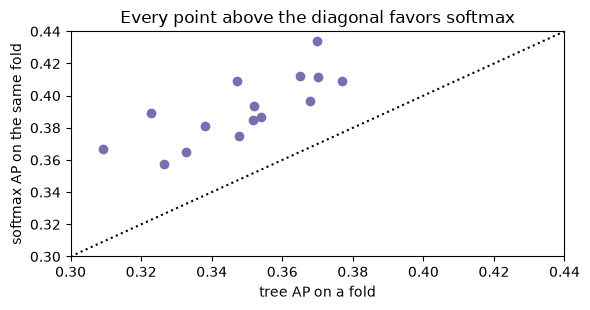

In [6]:
repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=438)
tree = create_student_algorithm("decision_tree", max_depth=4, min_samples_leaf=100)
softmax = make_pipeline(
    StandardScaler(),
    create_student_algorithm("softmax_regression", l2_penalty=0.1, learning_rate=0.5),
)
tree_ap = cross_val_score(tree, dev_x, dev_y, cv=repeated, scoring="average_precision")
softmax_ap = cross_val_score(softmax, dev_x, dev_y, cv=repeated, scoring="average_precision")
difference = softmax_ap - tree_ap

print(f"student tree (depth 4, leaf 100): AP {tree_ap.mean():.3f} ± {tree_ap.std():.3f}")
print(f"student softmax:        AP {softmax_ap.mean():.3f} ± {softmax_ap.std():.3f}")
print(f"softmax − tree, per fold: {difference.mean():.3f} ± {difference.std():.3f}; "
      f"softmax better in {(difference > 0).sum()} of {difference.size} folds")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.scatter(tree_ap, softmax_ap, color="#7570b3")
low, high = 0.3, 0.44
ax.plot([low, high], [low, high], ":", color="black")
ax.set(xlim=(low, high), ylim=(low, high), xlabel="tree AP on a fold",
       ylabel="softmax AP on the same fold", title="Every point above the diagonal favors softmax")
plt.tight_layout()

Softmax regression ranks better than the selected tree on **every one of the 15 folds**, by about 0.04 AP. That gap is several times the fold-to-fold spread of the difference, so it is not noise. On these data a single tree's flexibility costs more in variance and coarse ranking than it gains in interactions, consistent with the nearly additive pattern in §2.

## 8. The rules a product manager would read

Accuracy is not the tree's only value. A depth-3 tree, fitted on all development users, is a set of eight readable segments.

if activity_days <= 10.50:
    if n_days_after_onboarding <= 1715.50:
        if duration_minutes_drives <= 1933.33:
            leaf (n=1099): 0: 0.64, 1: 0.36
        else:  # duration_minutes_drives > 1933.33
            leaf (n=638): 0: 0.52, 1: 0.48
    else:  # n_days_after_onboarding > 1715.50
        if activity_days <= 3.50:
            leaf (n=641): 0: 0.65, 1: 0.35
        else:  # activity_days > 3.50
            leaf (n=1245): 0: 0.80, 1: 0.20
else:  # activity_days > 10.50
    if activity_days <= 18.50:
        if n_days_after_onboarding <= 1456.50:
            leaf (n=1150): 0: 0.79, 1: 0.21
        else:  # n_days_after_onboarding > 1456.50
            leaf (n=1586): 0: 0.89, 1: 0.11
    else:  # activity_days > 18.50
        if n_days_after_onboarding <= 1272.50:
            leaf (n=1580): 0: 0.90, 1: 0.10
        else:  # n_days_after_onboarding > 1272.50
            leaf (n=2785): 0: 0.95, 1: 0.05


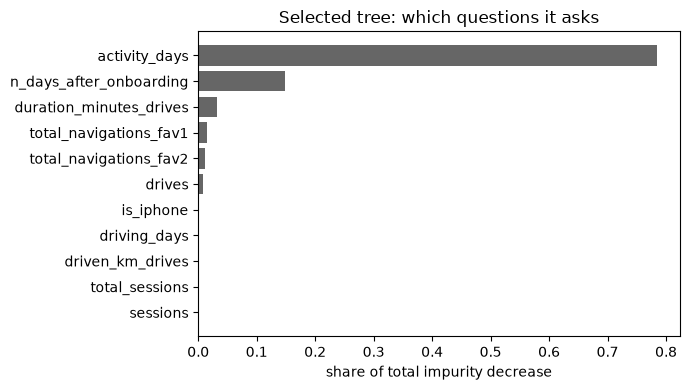

In [7]:
readable = create_student_algorithm("decision_tree", max_depth=3).fit(dev_x, dev_y)
print(readable.export_text(feature_names, decimals=2))

importance = pd.Series(
    create_student_algorithm("decision_tree", max_depth=4, min_samples_leaf=100)
    .fit(dev_x, dev_y).feature_importances_,
    index=feature_names,
).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color="#666666")
ax.set(xlabel="share of total impurity decrease", title="Selected tree: which questions it asks")
plt.tight_layout()

**How a PM could read this.** Each leaf shows the share of retained (0) and churned (1) users in that segment.

- **Highest risk (about 48% churn, 2.7× average):** users active on 10 days or fewer, with tenure under about 1,700 days, who nonetheless drove more than about 1,900 minutes this month. These are infrequent but intense users, the "short-term heavy users" pattern I found in my earlier analysis, and a natural target for a dedicated campaign.
- **Lowest risk (about 5%):** users active on more than 18 days with long tenure.
- In the selected depth-4 tree, activity days account for about 79% of the impurity reduction and tenure for about 15%, the same two signals that dominate the linear model. Minutes driven contributes about 3%.

These rules come from development data and a single tree. §9 shows they are less stable than they look, so they are hypotheses for a PM to test, not established segments.

## 9. Failure analysis

**Does the tree catch the active churners that softmax missed?** At a fixed outreach budget (the riskiest 20% of users, using out-of-fold scores), we compare which churners each model reaches.

In [8]:
softmax_oof = cross_val_predict(softmax, dev_x, dev_y, cv=cv, method="predict_proba")[:, 1]
tree_oof = oof[("gini", 4, 100)]
churners = dev_y.to_numpy() == 1
activity_group = pd.cut(dev_x["activity_days"], [-1, 10, 20, 31],
                        labels=["0–10 days", "11–20 days", "21–31 days"]).to_numpy()

reach = {}
for name, scores in (("student softmax", softmax_oof), ("student tree", tree_oof)):
    flagged = scores >= np.quantile(scores, 0.8)
    reach[name] = pd.Series(flagged[churners]).groupby(activity_group[churners]).mean()
reach = pd.DataFrame(reach)
reach.loc["all churners"] = [
    (s >= np.quantile(s, 0.8))[churners].mean() for s in (softmax_oof, tree_oof)
]
reach["churners in group"] = list(pd.Series(activity_group[churners]).value_counts().sort_index()) + [churners.sum()]
display(reach.round(3))

,student softmax,student tree,churners in group
0–10 days,0.691,0.688,1183
11–20 days,0.090,0.082,478
21–31 days,0.000,0.000,241
all churners,0.452,0.448,1902


No. Both models reach about 69% of churners active on 10 days or fewer, under 10% of those active on 11–20 days, and **none** of the 241 churners active on more than 20 days. The tree reaches marginally fewer churners overall (44.8% vs 45.2%). The blind spot is in the *data*, not the model family: nothing in one month of usage counts separates an active user who is about to leave from one who will stay.

**How stable are the rules?** If the segments in §8 are real structure, small changes in the training sample should not change them much. We refit the depth-3 rule tree from §8 on 30 bootstrap resamples of the development users and record the questions it asks at the top two levels, and whether the "heavy driving" question (minutes driven, under the inactive-and-newer branch) reappears.

In [9]:
rng = np.random.default_rng(438)
records = []
for _ in range(30):
    sample = rng.integers(0, len(dev_x), len(dev_x))
    fitted = create_student_algorithm("decision_tree", max_depth=3).fit(
        dev_x.iloc[sample], dev_y.iloc[sample])
    t = fitted.tree_

    def question(node):
        return feature_names[t["feature"][node]] if t["left"][node] != -1 else "leaf"

    left, right = t["left"][0], t["right"][0]
    records.append({
        "root": f"{question(0)} ≤ {t['threshold'][0]:.1f}",
        "left child": question(left),
        "right child": question(right),
        "left-left grandchild": question(t["left"][left]) if t["left"][left] != -1 else "leaf",
    })
records = pd.DataFrame(records)
for column in records:
    print(f"{column}:", records[column].value_counts().to_dict())

root: {'activity_days ≤ 8.5': 11, 'activity_days ≤ 10.5': 10, 'activity_days ≤ 12.5': 6, 'activity_days ≤ 11.5': 2, 'activity_days ≤ 13.5': 1}
left child: {'n_days_after_onboarding': 29, 'activity_days': 1}
right child: {'activity_days': 14, 'driving_days': 9, 'n_days_after_onboarding': 7}
left-left grandchild: {'duration_minutes_drives': 17, 'activity_days': 11, 'driven_km_drives': 1, 'n_days_after_onboarding': 1}


The picture is mixed, and worth stating precisely:

- **Stable:** every resample asks about active days first, and 29 of 30 then ask about tenure for the less active users. The two main signals are real.
- **Unstable:** the root threshold moves between 8.5 and 13.5 days and matches the 10.5 in §8 in only 10 of 30 resamples. The question asked of the *more* active users changes between active days, driving days, and tenure.
- **The "heavy driving" segment** (minutes driven, under the inactive-and-newer branch) reappears in only 17 of 30 resamples. It is a plausible hypothesis, not an established segment.

This is the well-known **high variance** of single trees: small changes in the data change the thresholds and the deeper questions. It makes detailed rules unreliable as standalone segments, and it is what averaging many trees (bagging and random forests, lecture 15) is designed to reduce.

**Failure sources.**

- *Data / task formulation:* active churners are indistinguishable from active retained users in these features, so no model family will fix this alone.
- *Model variance:* single-tree segments below the root are unstable across resamples.
- *Coarse ranking:* a depth-4 tree outputs at most 16 distinct scores, so its ranking has many ties.
- *Implementation:* none found. The student tree matches scikit-learn exactly.

## 10. Conclusion and decision

**Answer.** On these data, decision rules do **not** find meaningful churn structure that the linear score misses. The selected student tree (depth 4, at least 100 users per leaf) reaches CV AP ≈ 0.35–0.36 against ≈ 0.39 for softmax regression and is worse on all 15 paired folds. It misses the same active churners. The churn signal is close to additive in activity and tenure, which a linear log-odds model represents efficiently.

**Decision.** Do **not** promote the single tree. Keep it in the project for two roles:

1. **Communication:** the depth-3 rules are a useful, honest summary for a PM ("inactive + newer + heavy driving = highest risk"), labeled as hypotheses.
2. **Building block:** `ClassificationTree` already supports per-node feature sampling, so it is ready to become the base learner of a student random forest.

The sealed test set was not used. The softmax model from notebook 02 remains the baseline to beat.

**Next steps.**

1. Lecture 15: student **random forest** (bagging + feature sampling) and **gradient boosting**, with the XGBoost model from my earlier analysis as a trusted reference. Does variance reduction close the 0.04 AP gap?
2. Engineered features (for example the share of lifetime sessions that happened this month) to give any model a handle on *changes* in behavior.
3. A cross-family model-selection notebook (lecture 16) that opens the test set once for the final candidates.